# Analyse géospatiale de villes avec Pandas et GeoPandas

Chargement, nettoyage et analyse d'un jeu de données de 100 grandes villes, conversion en GeoDataFrame, jointure spatiale avec les frontières des pays, visualisation cartographique et tests unitaires.

**Données** (à placer dans le dossier `data/`) :
- `villes.csv` : colonnes `ville`, `pays`, `population`, `latitude`, `longitude` (source : https://simplemaps.com/data/world-cities)
- `pays.shp` (+ `.shx`, `.dbf`) : frontières des pays (source : https://public.opendatasoft.com/explore/dataset/world-administrative-boundaries/export/)


In [ ]:
# Chargement des données
import pandas as pd
import geopandas as gpd

villes = pd.read_csv("data/villes.csv")
pays = gpd.read_file("data/pays.shp")

print(villes.head())

       ville  latitude  longitude       pays  population
0      Tokyo   35.6897   139.6922      Japan  37732000.0
1    Jakarta   -6.1750   106.8275  Indonesia  33756000.0
2      Delhi   28.6100    77.2300      India  32226000.0
3  Guangzhou   23.1300   113.2600      China  26940000.0
4     Mumbai   19.0761    72.8775      India  24973000.0


In [13]:
print(pays.head())

                                            geometry
0  MULTIPOLYGON (((117.70361 4.16341, 117.70361 4...
1  MULTIPOLYGON (((117.70361 4.16341, 117.69711 4...
2  MULTIPOLYGON (((-69.51009 -17.50659, -69.50611...
3  POLYGON ((-69.51009 -17.50659, -69.51009 -17.5...
4  MULTIPOLYGON (((-69.51009 -17.50659, -69.63832...


# Informations générales

In [17]:
villes.info()
print("")
pays.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   ville       100 non-null    object 
 1   latitude    99 non-null     float64
 2   longitude   99 non-null     float64
 3   pays        99 non-null     object 
 4   population  99 non-null     float64
dtypes: float64(3), object(2)
memory usage: 4.0+ KB

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 258 entries, 0 to 257
Data columns (total 1 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   geometry  258 non-null    geometry
dtypes: geometry(1)
memory usage: 2.1 KB


# Statistiques de base

Le jeu de données contient 100 villes avec une valeur manquante pour les colonnes: `latitude`, `longitude`, `population`, `pays`.
La population **moyenne** est d’environ 11,5 millions d’habitants, avec une **médiane** autour de 9 millions, ce qui montre une forte dispersion des populations.
Certaines villes très peuplées tirent la moyenne vers le haut, ce qui est confirmé par un écart-type élevé.

In [27]:
villes.describe()
#villes.shape

        latitude   longitude    population
count  99.000000   99.000000  9.900000e+01
mean   23.228411   69.848768  1.150485e+07
std    17.680497   67.786261  6.575841e+06
min   -34.603300 -118.406800  5.708191e+06
25%    19.254700   38.448750  6.989618e+06
50%    27.284000  106.550400  8.970014e+06
75%    34.338050  115.198500  1.439650e+07
max    55.755800  139.692200  3.773200e+07

## Total des valeurs manquantes

In [23]:
villes.isnull().sum()

,0
ville,0
latitude,1
longitude,1
pays,1
population,1


# Suppression des valeurs manquantes

In [24]:
villes = villes.dropna(subset=["latitude", "longitude", "pays", "population"])

In [25]:
villes.shape

(99, 5)

# Vérification de la suppression

In [26]:
villes.isnull().sum()

,0
ville,0
latitude,0
longitude,0
pays,0
population,0


# Nettoyage et filtrage des données

In [31]:
# Nettoyage
# Une population ne peut pas etre negative, encore moins nulle pour une ville

# population incorrecte
villes = villes[villes["population"] > 0]

# Latitude et longitude incorrecte
# D'apres nos recherches, latitude ∈ [-90, 90] et longitude ∈ [-180, 180]

villes = villes[
    (villes["latitude"] >= -90) & (villes["latitude"] <= 90) &
    (villes["longitude"] >= -180) & (villes["longitude"] <= 180)
]

In [32]:
villes.info()

<class 'pandas.core.frame.DataFrame'>
Index: 99 entries, 0 to 99
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   ville       99 non-null     object 
 1   latitude    99 non-null     float64
 2   longitude   99 non-null     float64
 3   pays        99 non-null     object 
 4   population  99 non-null     float64
dtypes: float64(3), object(2)
memory usage: 4.6+ KB


In [33]:
villes.isnull().sum()

,0
ville,0
latitude,0
longitude,0
pays,0
population,0


# Statistiques descriptives sur la population
La population des villes varie fortement, allant d’environ 5,7 millions à plus de 37 millions d’habitants.
La population médiane est proche de 9 millions, ce qui indique que la majorité des villes sont des grandes métropoles, tandis que quelques villes très peuplées augmentent la moyenne.

In [34]:
villes["population"].describe()

,population
count,9.900000e+01
mean,1.150485e+07
std,6.575841e+06
min,5.708191e+06
25%,6.989618e+06
50%,8.970014e+06
75%,1.439650e+07
max,3.773200e+07


# Conversion du Dataframe en Geodataframe

In [35]:
import geopandas as gpd

# villes est le DataFrame Pandas déjà nettoyé
villes_gdf = gpd.GeoDataFrame(
    villes,
    geometry=gpd.points_from_xy(villes["longitude"], villes["latitude"]),
    crs="EPSG:4326"  # coordonnées GPS (lat/lon)
)

villes_gdf.head()

       ville  latitude  longitude       pays  population  \
0      Tokyo   35.6897   139.6922      Japan  37732000.0   
1    Jakarta   -6.1750   106.8275  Indonesia  33756000.0   
2      Delhi   28.6100    77.2300      India  32226000.0   
3  Guangzhou   23.1300   113.2600      China  26940000.0   
4     Mumbai   19.0761    72.8775      India  24973000.0   

                   geometry  
0  POINT (139.6922 35.6897)  
1   POINT (106.8275 -6.175)  
2       POINT (77.23 28.61)  
3      POINT (113.26 23.13)  
4   POINT (72.8775 19.0761)  

In [36]:
pays.geometry.type.value_counts()

,count
MultiPolygon,151
Polygon,107


Le shapefile des pays contient des géométries de type Polygon et MultiPolygon, ce qui est normal puisque certains pays sont constitués de plusieurs territoires ou îles.

In [37]:
# verifier le système de coordonnées de mes 2 couches géographiques
print(villes_gdf.crs)
print(pays.crs)

EPSG:4326
None


Ici on voit que `pays.crs = None`. Ce qui signifie que GeoPandas ne sait pas dans quel système de coordonnées sont les pays.
Pour corriger cela, comme mes villes sont déjà en `EPSG:4326`, la solution logique est d’attribuer ce CRS aux pays, grâce à `set_crs`, qui va indiquer comment lire les coordonnées existantes.

In [39]:
pays = pays.set_crs(epsg=4326)

# Jointure spatiale (trouver le pays de chaque ville)

In [40]:
villes_avec_pays = gpd.sjoin(
    villes_gdf,
    pays,
    how="left",
    predicate="within"
)

villes_avec_pays.head()

       ville  latitude  longitude       pays  population  \
0      Tokyo   35.6897   139.6922      Japan  37732000.0   
1    Jakarta   -6.1750   106.8275  Indonesia  33756000.0   
2      Delhi   28.6100    77.2300      India  32226000.0   
3  Guangzhou   23.1300   113.2600      China  26940000.0   
4     Mumbai   19.0761    72.8775      India  24973000.0   

                   geometry  index_right  
0  POINT (139.6922 35.6897)        189.0  
1   POINT (106.8275 -6.175)          0.0  
2       POINT (77.23 28.61)          8.0  
3      POINT (113.26 23.13)          9.0  
4   POINT (72.8775 19.0761)          8.0  

In [41]:
# Pour verifier que a chaque pays a bien été attribué une ville
villes_avec_pays["index_right"].isnull().sum()

np.int64(4)

In [42]:
villes_avec_pays[villes_avec_pays["index_right"].isnull()]

            ville  latitude  longitude       pays  population  \
19          Lagos    6.4550     3.3841    Nigeria  16637000.0   
53       Quanzhou   24.8744   118.6757      China   8782285.0   
64  Dar es Salaam   -6.8161    39.2803   Tanzania   7962000.0   
67      Hong Kong   22.3000   114.2000  Hong Kong   7450000.0   

                    geometry  index_right  
19      POINT (3.3841 6.455)          NaN  
53  POINT (118.6757 24.8744)          NaN  
64   POINT (39.2803 -6.8161)          NaN  
67        POINT (114.2 22.3)          NaN  

La jointure spatiale a permis d’associer la majorité des villes à un pays.
Cependant, quatre villes n’ont pas été associées à un polygone de pays, probablement en raison d’imprécisions dans les coordonnées ou dans les frontières du shapefile.

# Visualisation des données

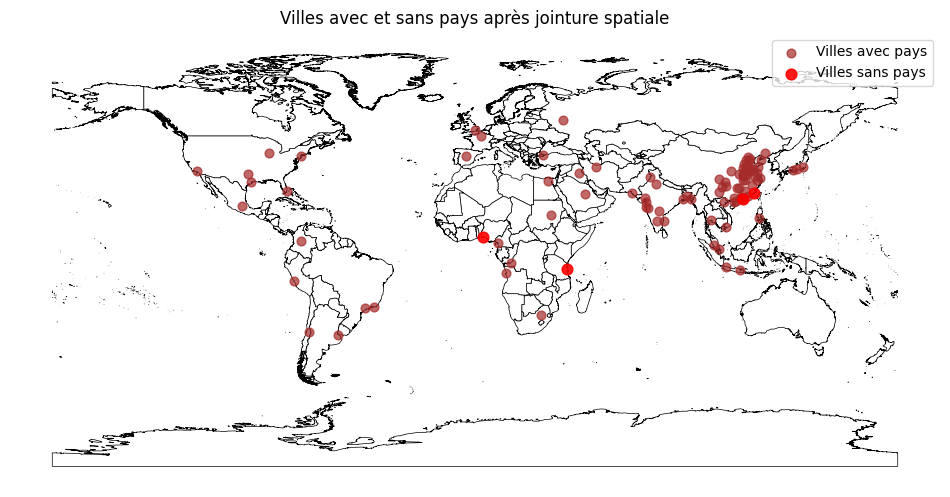

In [51]:
import matplotlib.pyplot as plt

# Séparer les villes avec pays et sans pays
villes_avec_pays_ok = villes_avec_pays[villes_avec_pays["index_right"].notnull()]
villes_sans_pays = villes_avec_pays[villes_avec_pays["index_right"].isnull()]

# pour Créer la figure
fig, ax = plt.subplots(figsize=(12, 6))

# Dessiner les frontières des pays
pays.plot(
    ax=ax,
    edgecolor="black",
    linewidth=0.5,
    color="white"
)

# Dessiner les villes qui ont un pays (en marron)
villes_avec_pays_ok.plot(
    ax=ax,
    color="brown",
    markersize=40,
    alpha=0.7,
    label="Villes avec pays"
)

# Dessiner les villes sans pays (en rouge)
villes_sans_pays.plot(
    ax=ax,
    color="red",
    markersize=60,
    alpha=0.9,
    label="Villes sans pays"
)

# Ajouter un titre et une légende
ax.set_title("Villes avec et sans pays après jointure spatiale")
ax.legend()
ax.set_axis_off()

# Affichage de la carte
plt.show()


Les frontières des pays ont été affichées à partir du shapefile.
Les villes associées à un pays après la jointure spatiale sont affichées en marron, tandis que les villes non associées à un pays sont mises en évidence en rouge.

# I. Tests Unitaires
## 1. Fonctions à tester

In [46]:
import pandas as pd
import geopandas as gpd

def nettoyer_villes(villes_df):
    # On enlève les lignes où il manque des infos essentielles
    villes_df = villes_df.dropna(subset=["latitude", "longitude", "pays","population"])

    # On enlève les coordonnées impossibles
    villes_df = villes_df[
        (villes_df["latitude"] >= -90) & (villes_df["latitude"] <= 90) &
        (villes_df["longitude"] >= -180) & (villes_df["longitude"] <= 180)
    ]

    # On enlève les populations incorrectes
    villes_df = villes_df[villes_df["population"] > 0]

    return villes_df


def convertir_en_geodf(villes_df):
    # Transforme le DataFrame en GeoDataFrame avec des points
    villes_gdf = gpd.GeoDataFrame(
        villes_df.copy(),
        geometry=gpd.points_from_xy(villes_df["longitude"], villes_df["latitude"]),
        crs="EPSG:4326"
    )
    return villes_gdf


def faire_jointure_spatiale(villes_gdf, pays_gdf):
    # Assurer le CRS pour éviter les problèmes
    if pays_gdf.crs is None:
        pays_gdf = pays_gdf.set_crs("EPSG:4326")
    else:
        pays_gdf = pays_gdf.to_crs(villes_gdf.crs)

    # Jointure spatiale: on veut savoir dans quel pays est chaque ville
    res = gpd.sjoin(villes_gdf, pays_gdf, how="left", predicate="within")
    return res


## 2. Unitest

In [47]:
import unittest
import pandas as pd
import geopandas as gpd

# =========================
# Tests unitaires
# =========================

class TestGeoAnalyse(unittest.TestCase):


    # Tests pour nettoyer_villes

    def test_nettoyer_villes_supprime_valeurs_manquantes(self):
        # Ici la 2e ligne a une latitude manquante -> doit être supprimée
        df = pd.DataFrame({
            "ville": ["A", "B"],
            "latitude": [10.0, None],
            "longitude": [20.0, 30.0],
            "pays": ["TestLand", "TestLand"],
            "population": [1000, 2000]
        })

        df_net = nettoyer_villes(df)

        self.assertEqual(len(df_net), 1)
        self.assertEqual(df_net.iloc[0]["ville"], "A")

    def test_nettoyer_villes_filtre_coordonnees_invalides(self):
        # latitude 200 est impossible -> la ligne B doit être supprimée
        df = pd.DataFrame({
            "ville": ["A", "B"],
            "latitude": [10.0, 200.0],
            "longitude": [20.0, 30.0],
            "pays": ["TestLand", "TestLand"],
            "population": [1000, 2000]
        })

        df_net = nettoyer_villes(df)

        self.assertEqual(len(df_net), 1)
        self.assertEqual(df_net.iloc[0]["ville"], "A")

    def test_nettoyer_villes_filtre_population_invalide(self):
        # population négative -> la ligne B doit être supprimée
        df = pd.DataFrame({
            "ville": ["A", "B"],
            "latitude": [10.0, 11.0],
            "longitude": [20.0, 21.0],
            "pays": ["TestLand", "TestLand"],
            "population": [1000, -5]
        })

        df_net = nettoyer_villes(df)

        self.assertEqual(len(df_net), 1)
        self.assertEqual(df_net.iloc[0]["ville"], "A")

    def test_nettoyer_villes_supprime_si_pays_manquant(self):
        # pays manquant -> la ligne B doit être supprimée
        df = pd.DataFrame({
            "ville": ["A", "B"],
            "latitude": [10.0, 11.0],
            "longitude": [20.0, 21.0],
            "pays": ["TestLand", None],
            "population": [1000, 2000]
        })

        df_net = nettoyer_villes(df)

        self.assertEqual(len(df_net), 1)
        self.assertEqual(df_net.iloc[0]["ville"], "A")


    # Tests pour convertir_en_geodf


    def test_convertir_en_geodf_cree_geometry_et_crs(self):
        df = pd.DataFrame({
            "ville": ["A"],
            "latitude": [10.0],
            "longitude": [20.0],
            "pays": ["TestLand"],
            "population": [1000]
        })

        gdf = convertir_en_geodf(df)

        self.assertIsInstance(gdf, gpd.GeoDataFrame)
        self.assertIn("geometry", gdf.columns)
        self.assertEqual(str(gdf.crs), "EPSG:4326")

        # Vérifier que c'est bien un point
        self.assertEqual(gdf.geometry.iloc[0].geom_type, "Point")


    # Tests pour faire_jointure_spatiale

    def test_jointure_spatiale_trouve_un_pays(self):
        # 1 ville au point (0,0)
        df = pd.DataFrame({
            "ville": ["A"],
            "latitude": [0.0],
            "longitude": [0.0],
            "pays": ["?"],
            "population": [1000]
        })
        villes_gdf = convertir_en_geodf(df)

        # 1 pays = un carré autour du point (0,0)
        # WKT = texte qui décrit un polygone
        poly = gpd.GeoSeries.from_wkt([
            "POLYGON((-1 -1, -1 1, 1 1, 1 -1, -1 -1))"
        ])
        pays_gdf = gpd.GeoDataFrame(
            {"nom_pays": ["TestLand"]},
            geometry=poly,
            crs="EPSG:4326"
        )

        res = faire_jointure_spatiale(villes_gdf, pays_gdf)

        # GeoPandas ajoute index_right si la jointure a eu lieu
        self.assertIn("index_right", res.columns)

        # la ville est dans le carré donc on doit trouver un pays
        self.assertFalse(pd.isna(res.loc[0, "index_right"]))

        # on vérifie que la colonne du pays est bien jointe
        self.assertEqual(res.loc[0, "nom_pays"], "TestLand")

    def test_jointure_spatiale_none_si_pas_dans_polygone(self):
        # Ville loin du polygone
        df = pd.DataFrame({
            "ville": ["A"],
            "latitude": [50.0],
            "longitude": [50.0],
            "pays": ["?"],
            "population": [1000]
        })
        villes_gdf = convertir_en_geodf(df)

        poly = gpd.GeoSeries.from_wkt([
            "POLYGON((-1 -1, -1 1, 1 1, 1 -1, -1 -1))"
        ])
        pays_gdf = gpd.GeoDataFrame(
            {"nom_pays": ["TestLand"]},
            geometry=poly,
            crs="EPSG:4326"
        )

        res = faire_jointure_spatiale(villes_gdf, pays_gdf)

        # la ville est en dehors donc index_right doit être NaN
        self.assertTrue(pd.isna(res.loc[0, "index_right"]))


if __name__ == "__main__":
    unittest.main(argv=[""], exit=False, verbosity=2)


test_convertir_en_geodf_cree_geometry_et_crs (__main__.TestGeoAnalyse.test_convertir_en_geodf_cree_geometry_et_crs) ... ok
test_jointure_spatiale_none_si_pas_dans_polygone (__main__.TestGeoAnalyse.test_jointure_spatiale_none_si_pas_dans_polygone) ... ok
test_jointure_spatiale_trouve_un_pays (__main__.TestGeoAnalyse.test_jointure_spatiale_trouve_un_pays) ... ok
test_nettoyer_villes_filtre_coordonnees_invalides (__main__.TestGeoAnalyse.test_nettoyer_villes_filtre_coordonnees_invalides) ... ok
test_nettoyer_villes_filtre_population_invalide (__main__.TestGeoAnalyse.test_nettoyer_villes_filtre_population_invalide) ... ok
test_nettoyer_villes_supprime_si_pays_manquant (__main__.TestGeoAnalyse.test_nettoyer_villes_supprime_si_pays_manquant) ... ok
test_nettoyer_villes_supprime_valeurs_manquantes (__main__.TestGeoAnalyse.test_nettoyer_villes_supprime_valeurs_manquantes) ... ok

----------------------------------------------------------------------
Ran 7 tests in 0.055s

OK
